<a href="https://colab.research.google.com/github/aryanshenoy02/Banking-Fraud-Detection/blob/main/notebooks/autoencoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

# uploaded is a dict like {'whatever_name.csv': b'...bytes...'}
# next(iter(...)) grabs the first (and only) key, i.e. the filename
filename = next(iter(uploaded))

try:
    # Skipping the first 3 rows of metadata to start directly from the table headers
    df = pd.read_csv(filename, skiprows=3)
    print(f"Successfully loaded '{filename}' by skipping the metadata rows:")
    display(df.head(10))
except Exception as e:
    print(f"Error reading CSV: {e}")

Saving AryanTransactions.csv to AryanTransactions (1).csv
Successfully loaded 'AryanTransactions (1).csv' by skipping the metadata rows:


,Date,Time,Transaction Details,Transaction ID,UTR,Transaction Type,Credit/debit instrument,Amount
0,"Nov 07, 2026",10:19 pm,Paid to MYNTRA,T2611072219424673654963,4.455930e+11,DEBIT,Paid by 652926XXXXXXXX42,396.0
1,"Nov 07, 2026",12:20 pm,Paid to Gunavathi,T2611071220380263257149,1.816804e+11,DEBIT,Paid by 652926XXXXXXXX42,30.0
2,"Nov 03, 2026",04:46 pm,Paid to CHINCHU FEBIN,T2611031646116467551004,6.983029e+10,DEBIT,Paid by 652926XXXXXXXX42,210.0
3,"Nov 03, 2026",01:30 pm,Paid to Mr GOVIND RAJU,T2611031330551147580177,2.781873e+11,DEBIT,Paid by 652926XXXXXXXX42,42.0
4,"Oct 29, 2026",07:42 pm,Paid to Noor AMC,T2610291942338322376037,2.179925e+11,DEBIT,Paid by XXXX1629,325.0
5,"Oct 29, 2026",04:03 pm,Received from Lokesh,T2610291603030111345797,1.443723e+11,CREDIT,Credited to XXXX1629,55.0
6,"Oct 29, 2026",02:51 pm,Received from PRANATHI J,T2610291451591043848939,1.320329e+11,CREDIT,Credited to XXXX1629,50.0
7,"Oct 29, 2026",12:50 pm,Paid to Google Asia Pacific Pte.Ltd,T2610291249594816905913,2.306949e+11,DEBIT,Paid by 652926XXXXXXXX42,40.0
8,"Oct 28, 2026",06:08 pm,Paid to Sapna Book House -Royal Meenakshi Mall...,T2610281808346921321303,8.619950e+11,DEBIT,Paid by 652926XXXXXXXX42,100.0
9,"Oct 28, 2026",06:07 pm,Paid to Sapna Book House -Royal Meenakshi Mall...,T2610281806569657263913,7.960780e+11,DEBIT,Paid by 652926XXXXXXXX42,30.0


In [ ]:
combined = df['Date'].astype(str) + ' ' + df['Time'].astype(str)


parsed = pd.to_datetime(
    combined.str.replace(r'\bSept\b', 'Sep', regex=True),
    format='%b %d, %Y %I:%M %p', #example - November 15, 2026 09:30 AM
    errors='coerce' #to replace unparseable data with NaT (Not a Time)
)

invalid_rows = df[parsed.isna()]

display(invalid_rows)

#boolean filtering to remove the invalid rows
df = df[parsed.notna()].copy()
#creating Datetime with no NaN values
df['Datetime'] = parsed[parsed.notna()]

,Date,Time,Transaction Details,Transaction ID,UTR,Transaction Type,Credit/debit instrument,Amount
388,This is an automatically generated statement. ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
389,of any errors in the statement at https://supp...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
390,terms-conditions/ for PhonePe Terms & Conditio...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
391,Disclaimer : Do not fall prey to fictitious of...,money circulation schemes and cheap funds,NaN,NaN,NaN,NaN,NaN,NaN
392,etc. through SMS,emails and calls. The contents of this email ...,NaN,NaN,NaN,NaN,NaN,NaN
393,the recipient specified in this document. If y...,please inform PhonePe at,NaN,NaN,NaN,NaN,NaN,NaN
394,https://support.phonepe.com/statement so that ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

# 1. Drop rows where all columns are NaN (if any exist at the end of the file)
df = df.dropna(how='all').copy()

# 2. Clean the 'Transaction Details' column
# We remove case-insensitive variations of "Paid to " and "Received from "
df['Transaction Details'] = df['Transaction Details'].str.replace(r'^(Paid to|Received from)\s+', '', case=False, regex=True)

# Sort chronologically so we can calculate the time difference forward in time
df = df.sort_values('Datetime').reset_index(drop=True)

# 4. Calculate the time difference between consecutive transactions (in hours)
df['Time_Diff_Hours'] = df['Datetime'].diff().dt.total_seconds() / 3600.0
df['Time_Diff_Hours'] = df['Time_Diff_Hours'].fillna(0)

# Display the cleaned and processed DataFrame
display(df[['Transaction Details', 'Transaction Type', 'Amount', 'Time_Diff_Hours']].head(10))

,Transaction Details,Transaction Type,Amount,Time_Diff_Hours
0,KA01AR2800,DEBIT,25.00,0.000000
1,JUBILANT FOODWORKS LTD,DEBIT,125.80,3.816667
2,Burger King,DEBIT,41.96,2.850000
3,Vighnesh (cheta) AMC,DEBIT,200.00,0.533333
4,Reliance Tours & Travels,DEBIT,6.00,18.633333
5,Day to Day Super market,DEBIT,40.00,5.916667
6,ZEPTO MARKETPLACE PRIVATE LIMITED,DEBIT,124.00,43.966667
7,BEST CUTZ,DEBIT,100.00,53.033333
8,BirthGiver(Amma),DEBIT,1.00,13.550000
9,Bhavya refreshment,DEBIT,80.00,3.750000


In [ ]:
import numpy as np

df['Counterparty_Transaction_Count'] = df.groupby('Transaction Details').cumcount()
df['hour'] = df['Datetime'].dt.hour
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['dayofweek'] = df['Datetime'].dt.dayofweek
df['is_new_counterparty'] = (df['Counterparty_Transaction_Count'] == 0).astype(int)
df['is_debit'] = (df['Transaction Type'] == 'DEBIT').astype(int)

In [ ]:
import re

def is_known_merchant(name):
    # Strip whitespace
    name = str(name).strip()

    # Pattern: looks like a raw ID — e.g. KA01AR2800
    # Characteristics: no spaces, mix of uppercase letters and digits, length < 15
    raw_id_pattern = r'^[A-Z0-9]{5,15}$'

    if re.match(raw_id_pattern, name):
        return 0  # Unknown — raw ID
    else:
        return 1  # Known — readable merchant name

df['is_known_merchant'] = df['Transaction Details'].apply(is_known_merchant)

In [ ]:
df_ = df.drop(columns = ['Date','Time','Transaction ID','UTR','Transaction Type','Credit/debit instrument','Datetime','hour','Transaction Details'])

In [ ]:
from sklearn.preprocessing import MinMaxScaler

cols_to_scale = ['Amount', 'Time_Diff_Hours', 'Counterparty_Transaction_Count']

scaler = MinMaxScaler()
df_[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers

class AnomalyDetector(Model):
  def __init__(self):
    super(AnomalyDetector, self).__init__()
    self.encoder = tf.keras.Sequential([
        layers.Dense(16, activation='relu'),
        layers.Dense(8, activation='relu'),
        layers.Dense(4, activation='relu')
    ])

    self.decoder = tf.keras.Sequential([
        layers.Dense(8, activation='relu'),
        layers.Dense(16, activation='relu'),
        layers.Dense(input_dim, activation='linear')
    ])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded

input_dim = df_.shape[1]
autoencoder = AnomalyDetector()
autoencoder.compile(optimizer='adam', loss='mse')

history = autoencoder.fit(
    df_, df_,
    epochs=50,
    batch_size=32,
    shuffle=True,
)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.5412
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.4853 
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.4037 
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.2509 
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0381 
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7971 
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5531 
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3967 
Epoch 9/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3124 
Epoch 10/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2652 
Epoch 11/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2380 
Epoch 12/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2202 
Epoch 13/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2082 
Epoch 14/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1999 
Epoch 15/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1943 
Epoch

In [ ]:
import numpy as np

# Get reconstructed output
reconstructions = autoencoder.predict(df_)

# Calculate MSE per transaction (mean across all 9 features)
mse = np.mean(np.power(df_ - reconstructions, 2), axis=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


In [ ]:
threshold = np.percentile(mse, 99)  # top 1% flagged as anomalies
print(f"Threshold: {threshold:.4f}")

df['reconstruction_error'] = mse
df['is_anomaly'] = (mse > threshold).astype(int)

# See what got flagged
print(df[df['is_anomaly'] == 1][['Transaction Details', 'Amount', 'reconstruction_error']].sort_values('reconstruction_error', ascending=False))

Threshold: 0.3045
    Transaction Details  Amount  reconstruction_error
295            NAGARAJU   253.0              0.380444
366              SWIGGY   670.0              0.376836
387              MYNTRA   396.0              0.368154
133            PRATHIMA    75.0              0.325333


In [ ]:
def compute_trust_multiplier(row, contacts):
    multiplier = 1.0

    # Known contact — strong trust signal
    if row['Transaction Details'] in contacts:
        multiplier *= 0.5

    if row['Transaction Details'] in known_corp:
        multiplier *= 0.8

    # Known merchant — moderate trust signal
    if row['is_known_merchant'] == 1:
        multiplier *= 0.7

    return multiplier

known_corp = [
    "AMAZON"
]
contacts = [
    "BHOOMIKA SRIDHAR",
    "NAGARAJU",
    "Mr Yuvan R",
    "BirthGiver(Amma)",
    "SWIGGY",
    "MYNTRA"
    ""
]

df['trust_multiplier'] = df.apply(
    lambda row: compute_trust_multiplier(row, contacts), axis=1
)

df['final_anomaly_score'] = df['reconstruction_error'] * df['trust_multiplier']

# Reapply threshold on final score
threshold_final = np.percentile(df['final_anomaly_score'], 90)
df['is_anomaly'] = (df['final_anomaly_score'] > threshold_final).astype(int)
print(df[df['is_anomaly'] == 1][['Transaction Details', 'Amount', 'reconstruction_error']].sort_values('reconstruction_error', ascending=False))

                  Transaction Details   Amount  reconstruction_error
295                          NAGARAJU   253.00              0.380444
366                            SWIGGY   670.00              0.376836
387                            MYNTRA   396.00              0.368154
133                          PRATHIMA    75.00              0.325333
178              Creed Comabt Fitness  2378.81              0.301397
226                            C BABA   108.00              0.283670
218                        KA01AR2804    30.00              0.260639
49                         KA01AR2881    30.00              0.258698
123                        KA01AR1140    50.00              0.258526
207                        KA01AR1140    30.00              0.256322
0                          KA01AR2800    25.00              0.252823
28   Withdrawal from UPI Lite closure  2039.16              0.248897
288                       STAR BAZAAR   504.36              0.248474
168               BMTC BUS KA51AK1

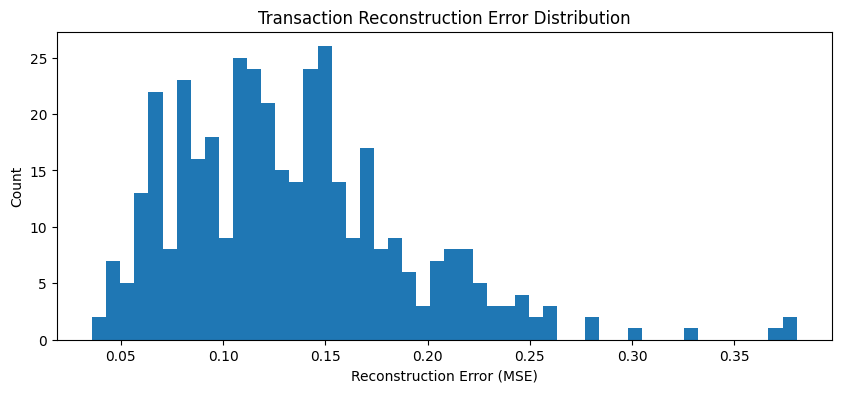

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.hist(mse, bins=50)
plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Count')
plt.title('Transaction Reconstruction Error Distribution')
plt.show()

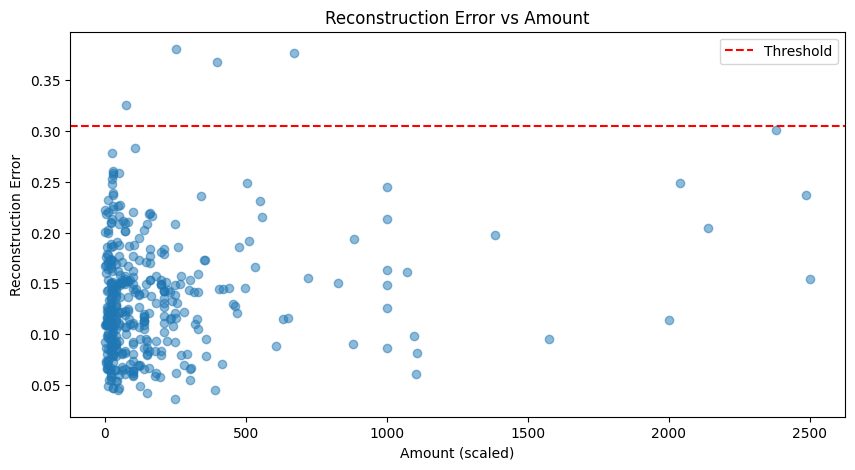

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(df['Amount'], df['reconstruction_error'], alpha=0.5)
plt.axhline(y=threshold, color='red', linestyle='--', label='Threshold')
plt.xlabel('Amount (scaled)')
plt.ylabel('Reconstruction Error')
plt.title('Reconstruction Error vs Amount')
plt.legend()
plt.show()

In [ ]:
def screen_transaction(new_row, df, autoencoder, scaler, contacts, threshold):
    """
    new_row: dict with raw transaction values
    Returns: the row with anomaly score and label appended
    """
    import pandas as pd
    import numpy as np

    # Step 1 — convert to dataframe
    new_df = pd.DataFrame([new_row])

    # Step 2 — feature engineering (same as training)
    new_df['hour'] = pd.to_datetime(new_df['Datetime']).dt.hour
    new_df['hour_sin'] = np.sin(2 * np.pi * new_df['hour'] / 24)
    new_df['hour_cos'] = np.cos(2 * np.pi * new_df['hour'] / 24)
    new_df['dayofweek'] = pd.to_datetime(new_df['Datetime']).dt.dayofweek
    new_df['is_known_merchant'] = new_df['Transaction Details'].apply(is_known_merchant)
    new_df['is_debit'] = (new_df['Transaction Type'] == 'DEBIT').astype(int)

    # Step 3 — drop columns not used in training
    feature_cols = [
        'Amount', 'Time_Diff_Hours', 'Counterparty_Transaction_Count',
        'hour_sin', 'hour_cos', 'dayofweek',
        'is_new_counterparty', 'is_debit', 'is_known_merchant'
    ]
    new_df = new_df[feature_cols]

    # Step 4 — scale using the SAME scaler
    cols_to_scale = ['Amount', 'Time_Diff_Hours', 'Counterparty_Transaction_Count']
    new_df[cols_to_scale] = scaler.transform(new_df[cols_to_scale])

    # Step 5 — get reconstruction error
    reconstruction = autoencoder.predict(new_df, verbose=0)
    error = np.mean(np.power(new_df.values - reconstruction, 2), axis=1)[0]

    # Step 6 — apply trust multiplier
    multiplier = compute_trust_multiplier(
        {'Transaction Details': new_row['Transaction Details'],
         'is_known_merchant': new_df['is_known_merchant'].values[0]},
        contacts
    )
    final_score = error * multiplier

    # Step 7 — label
    is_anomaly = int(final_score > threshold)

    print(f"Reconstruction Error : {error:.4f}")
    print(f"Trust Multiplier     : {multiplier}")
    print(f"Final Anomaly Score  : {final_score:.4f}")
    print(f"Threshold            : {threshold:.4f}")
    print(f"Label                : {'🚨 ANOMALY' if is_anomaly else '✅ NORMAL'}")

    return is_anomaly


new_transaction = {
    'Transaction Details': 'AMAZON',
    'Transaction Type': 'DEBIT',
    'Amount': 4999.00,
    'Datetime': '2026-11-18 02:15:00',  # 2am — suspicious
    'Time_Diff_Hours': 0.5,
    'Counterparty_Transaction_Count': 2,
    'is_new_counterparty': 0,
}

result = screen_transaction(
    new_transaction, df, autoencoder, scaler, contacts, threshold_final
)

Reconstruction Error : 0.7363
Trust Multiplier     : 0.8
Final Anomaly Score  : 0.5890
Threshold            : 0.1508
Label                : 🚨 ANOMALY
